<img src = "https://drive.google.com/uc?export=view&id=1A9dhO0gYByNJf9ya0SZmeCzZIeepRhsO" alt = "Encabezado MLDS" width = "100%">  </img>

# **Modelamiento y Validación**
---

Este notebook es una plantilla que le puede servir como guía para el cuarto entregable del proyecto aplicado.

## **0. Integrantes del equipo de trabajo**
---

Por favor incluya los nombres completos y número de identificación de los integrantes del equipo de trabajo:

1. ---**INGRESE SU RESPUESTA**---
2. ---**INGRESE SU RESPUESTA**---
3. ---**INGRESE SU RESPUESTA**---

## **1. Selección y diseño de modelos**
---

Seleccione el/los modelo/s a explorar para aplicar sobre el conjunto de datos. Recuerde que la selección del modelo está influenciada por diferentes factores.

Además, debe definir cuál es su problema:

- **Regresión**: se busca estimar un valor continúo a partir de los datos.
- **Clasificación**: permite estimar un valor categórico a partir de los datos.
- **Agrupamiento**: permite encontrar grupos de datos similares.
- **Otros modelos**: recuerde que dispone de otros tipos de tareas supervisadas y no supervisadas.

Justifique la selección y el diseño de los modelos a explorar.

---**INGRESE SU RESPUESTA**---

### 1.1. Definición del problema

Como se estableció en las fases anteriores, el proyecto aborda un problema de **clasificación supervisada binaria**, cuyo propósito es predecir la presencia (`1`) o ausencia (`0`) de enfermedad cardíaca mediante la variable objetivo `HeartDisease`.

Se utilizarán las variables predictoras identificadas y preparadas en la fase 3, correspondientes a características demográficas y clínicas de los registros. Se conservarán las decisiones de limpieza y tratamiento de datos previamente justificadas.

### 1.2. Selección y justificación de los modelos

Se propone explorar tres algoritmos de clasificación supervisada, seleccionados por sus diferentes mecanismos de aprendizaje y su pertinencia para el problema:

| Modelo | Características | Justificación |
|---|---|---|
| **Regresión logística** | Modelo lineal que estima probabilidades de pertenencia a una clase. | Proporciona una referencia supervisada relativamente sencilla e interpretable para evaluar la relación entre las características y la variable objetivo. |
| **K-Nearest Neighbors (KNN)** | Clasifica una observación según las clases de sus vecinos más cercanos. | Permite explorar si la similitud entre registros clínicos y demográficos resulta útil para identificar la presencia de enfermedad cardíaca. |
| **Random Forest** | Combina múltiples árboles de decisión para generar una clasificación. | Permite representar relaciones no lineales e interacciones entre variables sin imponer una relación lineal entre las características y la variable objetivo. |

La comparación de estos modelos permitirá estudiar tres enfoques diferentes: **lineal, basado en distancias y basado en conjuntos de árboles**.

Adicionalmente, se utilizará un clasificador de referencia (`DummyClassifier`) que predice la clase mayoritaria, con el propósito de establecer un desempeño mínimo frente al cual comparar los modelos entrenados.

### 1.3. Diseño general de la experimentación

Los modelos se entrenarán utilizando la partición de entrenamiento definida en la fase 3. Se aplicará **validación cruzada estratificada** para comparar su desempeño y explorar diferentes configuraciones de hiperparámetros.

El criterio principal de selección será el **F1-score de la clase positiva**, complementado con precisión, recall, exactitud y ROC-AUC. Se prestará especial atención al recall debido a la importancia de identificar los registros correspondientes a pacientes con enfermedad cardíaca.

El modelo seleccionado se evaluará posteriormente sobre el conjunto de prueba reservado, que no participará en el entrenamiento ni en la selección de hiperparámetros.

La implementación de los modelos, los experimentos y sus resultados se presentarán en la siguiente sección.

## **2. Entrenamiento del Modelo y Selección de Hiperparámetros**
---

Entrene el modelo y consiga la combinación eficiente de hiperparámetros para obtener un rendimiento óptimo.

Es importante visualizar los resultados de manera clara y comprensible. Para esto, **se deben utilizar tablas y gráficos** que muestren cómo cambian las métricas de desempeño del proceso de entrenamiento en función de los hiperparámetros probados. Algunas herramientas visuales útiles incluyen las *curvas de aprendizaje* y las *curvas de validación,* que nos permiten comparar el rendimiento del modelo con diferentes ajustes de hiperparámetros.

In [ ]:
# ---**INGRESE SU CÓDIGO**---

### 2.1. Estrategia de entrenamiento

Se entrenarán y compararán los tres algoritmos seleccionados: regresión logística, KNN y Random Forest, utilizando los datos y criterios de preparación establecidos en la fase 3.

Se conservará la partición estratificada del conjunto de datos:

- **Entrenamiento:** 80 % de los registros.
- **Prueba:** 20 % de los registros.
- **Semilla aleatoria:** `random_state=42`.

Para seleccionar los hiperparámetros se utilizará `GridSearchCV` con **validación cruzada estratificada de cinco pliegues**, aplicada exclusivamente al conjunto de entrenamiento.

Las transformaciones de preprocesamiento se integrarán en los `Pipeline` de Scikit-learn para evitar que la información de los pliegues de validación intervenga en el ajuste de imputadores, codificadores y escaladores.

El criterio principal de selección será el **F1-score de la clase positiva** (`HeartDisease=1`). También se registrarán precisión, recall, exactitud y ROC-AUC.

El conjunto de prueba permanecerá reservado para la sección 3, donde se evaluará el modelo seleccionado.

### 2.1. Recuperación y preparación de los datos

Las siguientes celdas reproducen las operaciones de carga, limpieza y partición establecidas en la fase 3, con el propósito de garantizar la ejecución independiente de este notebook.

El código de soporte se presenta contraído, conservando visibles únicamente las verificaciones necesarias para iniciar el modelamiento.

Las transformaciones estadísticas, como imputación, codificación y escalado, se integrarán posteriormente en los pipelines de entrenamiento para garantizar su ajuste dentro de la validación cruzada.

In [3]:
# @title Carga y limpieza de datos — Fase 3

import io
import zipfile
import requests
import numpy as np
import pandas as pd
from IPython.display import display

# Recuperar el conjunto de datos utilizado en la fase 3.
url = "https://www.kaggle.com/api/v1/datasets/download/fedesoriano/heart-failure-prediction"
response = requests.get(url, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as archivo:
    df_original = pd.read_csv(archivo.open("heart.csv"))

# Aplicar las reglas deterministas establecidas en la fase 3.
df = df_original.copy()
df["Cholesterol_missing"] = df["Cholesterol"].eq(0).astype(int)
df[["Cholesterol", "RestingBP"]] = df[["Cholesterol", "RestingBP"]].replace(0, np.nan)

# Verificar la consistencia con los resultados de la fase 3.
assert df_original.shape == (918, 12), "El conjunto de datos ha cambiado."
assert df["Cholesterol"].isna().sum() == 172
assert df["RestingBP"].isna().sum() == 1
assert df["Cholesterol_missing"].sum() == 172

resumen = pd.DataFrame({
    "Verificación": ["Registros conservados", "Variables originales",
                     "Colesterol faltante", "Presión arterial faltante",
                     "Indicador de colesterol"],
    "Resultado": [len(df), df_original.shape[1],
                  df["Cholesterol"].isna().sum(),
                  df["RestingBP"].isna().sum(),
                  df["Cholesterol_missing"].sum()]
})

display(resumen)
print("✓ Datos recuperados y limpieza verificada.")


,Verificación,Resultado
0,Registros conservados,918
1,Variables originales,12
2,Colesterol faltante,172
3,Presión arterial faltante,1
4,Indicador de colesterol,172


✓ Datos recuperados y limpieza verificada.


In [4]:
# @title Selección de variables y partición — Fase 3

from sklearn.model_selection import train_test_split

# Variables definidas en la fase 3.
num_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
cat_cols = ["Sex", "ChestPainType", "FastingBS", "RestingECG",
            "ExerciseAngina", "ST_Slope"]
indicator_cols = ["Cholesterol_missing"]
feature_cols = num_cols + cat_cols + indicator_cols

X = df[feature_cols].copy()
y = df["HeartDisease"].copy()

# Reproducir la partición de la fase 3.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Verificar integridad y separación.
assert len(X_train) == 734 and len(X_test) == 184
assert X_train.index.intersection(X_test.index).empty
assert X_train.columns.tolist() == feature_cols
assert y_train.isin([0, 1]).all() and y_test.isin([0, 1]).all()

resumen = pd.DataFrame({
    "Conjunto": ["Original", "Entrenamiento", "Prueba"],
    "Registros": [len(y), len(y_train), len(y_test)],
    "Clase 0 (%)": [100 * (v == 0).mean() for v in [y, y_train, y_test]],
    "Clase 1 (%)": [100 * (v == 1).mean() for v in [y, y_train, y_test]]
})

display(resumen.round(2))
print(f"Variables predictoras: {X.shape[1]} | Variable objetivo: HeartDisease")
print("✓ Partición estratificada verificada.")


,Conjunto,Registros,Clase 0 (%),Clase 1 (%)
0,Original,918,44.66,55.34
1,Entrenamiento,734,44.69,55.31
2,Prueba,184,44.57,55.43


Variables predictoras: 12 | Variable objetivo: HeartDisease
✓ Partición estratificada verificada.


### 2.2. Construcción de los pipelines de entrenamiento

Se construirán tres pipelines de clasificación supervisada utilizando `Pipeline` y `ColumnTransformer` de Scikit-learn.

Cada pipeline integrará el preprocesamiento definido en la fase 3 con el algoritmo correspondiente:

- **Regresión logística y KNN:** imputación de valores numéricos mediante la mediana, estandarización con `StandardScaler` y codificación de variables categóricas mediante `OneHotEncoder`.
- **Random Forest:** imputación y codificación de variables categóricas, sin estandarización numérica, dado que los árboles de decisión no requieren características en una escala común.

El indicador `Cholesterol_missing` se conservará como característica binaria, de acuerdo con la selección realizada en la fase 3.

La integración del preprocesamiento y el clasificador en un mismo pipeline permitirá que, durante la validación cruzada, las transformaciones se ajusten exclusivamente con los datos de entrenamiento de cada pliegue, evitando fugas de información hacia los datos de validación.

In [5]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Preprocesamiento numérico para regresión logística y KNN.
numeric_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocesamiento numérico para Random Forest.
numeric_unscaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Codificación de variables categóricas.
categorical = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Construir los preprocesadores.
preprocessor_scaled = ColumnTransformer([
    ("num", numeric_scaled, num_cols),
    ("cat", categorical, cat_cols),
    ("indicator", "passthrough", indicator_cols)
])

preprocessor_unscaled = ColumnTransformer([
    ("num", numeric_unscaled, num_cols),
    ("cat", categorical, cat_cols),
    ("indicator", "passthrough", indicator_cols)
])

# Construir los pipelines de clasificación.
pipelines = {
    "Regresión logística": Pipeline([
        ("preprocessor", preprocessor_scaled),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "KNN": Pipeline([
        ("preprocessor", preprocessor_scaled),
        ("model", KNeighborsClassifier())
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor_unscaled),
        ("model", RandomForestClassifier(random_state=42))
    ])
}

print("Pipelines construidos correctamente:")
for nombre, pipeline in pipelines.items():
    print(f"✓ {nombre}: {list(pipeline.named_steps.keys())}")


Pipelines construidos correctamente:
✓ Regresión logística: ['preprocessor', 'model']
✓ KNN: ['preprocessor', 'model']
✓ Random Forest: ['preprocessor', 'model']


### 2.3. Entrenamiento y selección de hiperparámetros

Se utilizará `GridSearchCV` para explorar diferentes configuraciones de los tres algoritmos seleccionados, aplicando **validación cruzada estratificada de cinco pliegues** sobre los datos de entrenamiento.

Se evaluarán los siguientes hiperparámetros:

| Modelo | Hiperparámetro | Valores |
|---|---|---|
| Regresión logística | `C` | 0.01, 0.1, 1, 10 |
| Regresión logística | `class_weight` | `None`, `balanced` |
| KNN | `n_neighbors` | 3, 5, 9, 15 |
| KNN | `weights` | `uniform`, `distance` |
| Random Forest | `n_estimators` | 100, 200 |
| Random Forest | `max_depth` | 5, 10, None |
| Random Forest | `min_samples_leaf` | 1, 5 |

El parámetro `C` controla la regularización de la regresión logística; en KNN se explorarán diferentes cantidades de vecinos y esquemas de ponderación; y en Random Forest se estudiarán la cantidad de árboles y las restricciones sobre su crecimiento.

La selección se realizará utilizando el **F1-score de la clase positiva** (`HeartDisease = 1`) como criterio principal. Adicionalmente, se registrarán recall, precisión, exactitud y ROC-AUC.

Todos los modelos se evaluarán utilizando los mismos cinco pliegues, con el propósito de mantener condiciones comparables.

El conjunto de prueba permanecerá reservado para la evaluación final de la sección 3.

In [6]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, f1_score, recall_score, precision_score

# Validación cruzada estratificada.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Hiperparámetros de cada modelo.
param_grids = {
    "Regresión logística": {
        "model__C": [0.01, 0.1, 1, 10],
        "model__class_weight": [None, "balanced"]
    },
    "KNN": {
        "model__n_neighbors": [3, 5, 9, 15],
        "model__weights": ["uniform", "distance"]
    },
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [5, 10, None],
        "model__min_samples_leaf": [1, 5]
    }
}

# Métricas de evaluación.
scoring = {
    "F1": make_scorer(f1_score, pos_label=1),
    "Recall": make_scorer(recall_score, pos_label=1),
    "Precision": make_scorer(precision_score, pos_label=1),
    "Accuracy": "accuracy",
    "ROC_AUC": "roc_auc"
}

total_configuraciones = sum(
    np.prod([len(v) for v in grid.values()]) for grid in param_grids.values()
)

print(f"Modelos: {len(pipelines)}")
print(f"Configuraciones: {total_configuraciones}")
print(f"Pliegues: {cv.n_splits}")
print(f"Ajustes de validación: {total_configuraciones * cv.n_splits}")


Modelos: 3
Configuraciones: 28
Pliegues: 5
Ajustes de validación: 140


In [9]:

import time

busquedas = {}
resultados = []

for nombre, pipeline in pipelines.items():
    inicio = time.perf_counter()

    busqueda = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[nombre],
        scoring=scoring,
        refit="F1",
        cv=cv,
        n_jobs=-1,
        return_train_score=True
    )

    busqueda.fit(X_train, y_train)
    busquedas[nombre] = busqueda

    idx = busqueda.best_index_
    cv_result = busqueda.cv_results_

    resultados.append({
        "Modelo": nombre,
        "F1": cv_result["mean_test_F1"][idx],
        "Recall": cv_result["mean_test_Recall"][idx],
        "Precision": cv_result["mean_test_Precision"][idx],
        "Accuracy": cv_result["mean_test_Accuracy"][idx],
        "ROC-AUC": cv_result["mean_test_ROC_AUC"][idx],
        "Tiempo (s)": time.perf_counter() - inicio,
        "Hiperparámetros": busqueda.best_params_
    })

    print(f"✓ {nombre}: F1 = {busqueda.best_score_:.4f}")

resultados_cv = pd.DataFrame(resultados).sort_values("F1", ascending=False)
#display(resultados_cv.round(4))


✓ Regresión logística: F1 = 0.8751
✓ KNN: F1 = 0.8720
✓ Random Forest: F1 = 0.8863


In [8]:
tabla_cv = resultados_cv.copy()
tabla_cv["Hiperparámetros"] = tabla_cv["Hiperparámetros"].apply(
    lambda params: ", ".join(f"{k.replace('model__', '')}={v}" for k, v in params.items())
)

display(tabla_cv[["Modelo", "F1", "Recall", "Precision",
                  "Accuracy", "ROC-AUC", "Hiperparámetros"]].round(4))

,Modelo,F1,Recall,Precision,Accuracy,ROC-AUC,Hiperparámetros
2,Random Forest,0.8863,0.9163,0.8589,0.8692,0.9332,"max_depth=5, min_samples_leaf=5, n_estimators=200"
0,Regresión logística,0.8751,0.8917,0.8604,0.8583,0.9256,"C=0.1, class_weight=None"
1,KNN,0.8720,0.8793,0.8650,0.8570,0.9162,"n_neighbors=15, weights=uniform"


### 2.4. Análisis de hiperparámetros mediante curvas de validación

Para analizar el efecto de los hiperparámetros sobre el desempeño de los clasificadores, se construirán curvas de validación utilizando los resultados obtenidos mediante `GridSearchCV`.

Se estudiará un hiperparámetro representativo de cada modelo:

- **Regresión logística:** `C`, que controla la intensidad de la regularización.
- **KNN:** `n_neighbors`, que determina la cantidad de vecinos utilizados para clasificar.
- **Random Forest:** `max_depth`, que limita la profundidad de los árboles.

En cada caso se mantendrán fijos los demás hiperparámetros en los valores de la mejor configuración encontrada para esa familia.

Se comparará el F1 medio de entrenamiento con el F1 medio de validación cruzada. Esta comparación permitirá identificar configuraciones con posibles problemas de sobreajuste o capacidad insuficiente de aprendizaje.

Los gráficos se construirán a partir de los resultados almacenados en `GridSearchCV`, sin realizar entrenamientos adicionales.

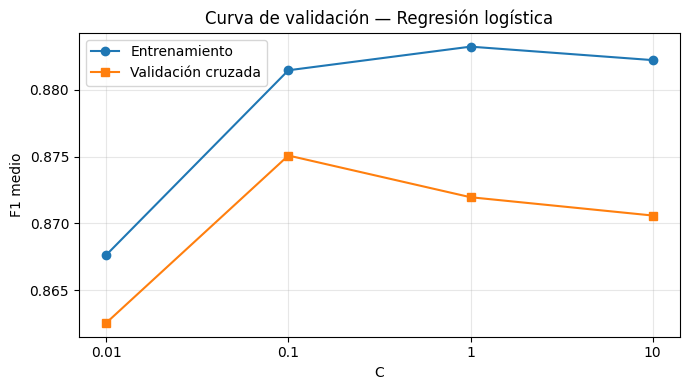

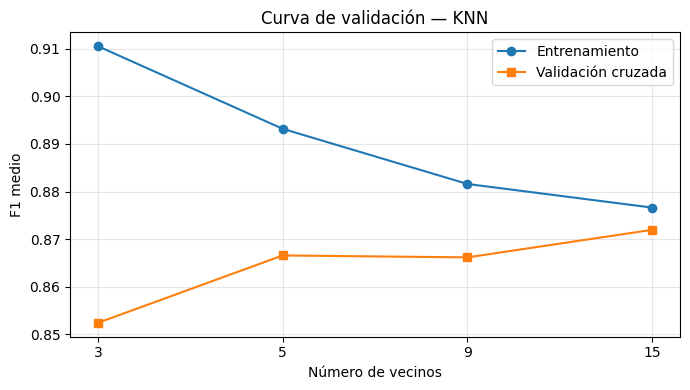

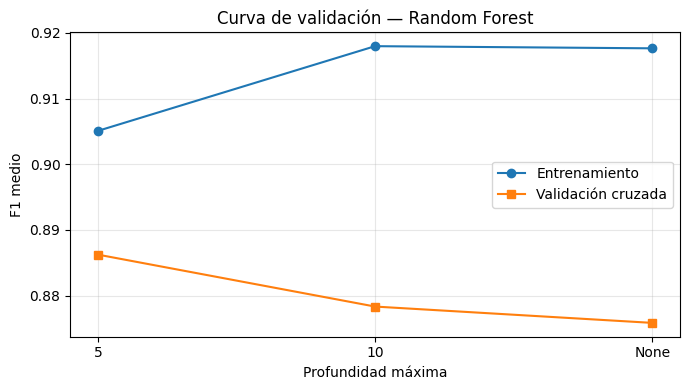

In [10]:

import matplotlib.pyplot as plt

def graficar_validacion(nombre, parametro, etiqueta):
    busqueda = busquedas[nombre]
    resultados = pd.DataFrame(busqueda.cv_results_)
    mejores = busqueda.best_params_

    # Mantener fijos los demás hiperparámetros.
    for clave, valor in mejores.items():
        if clave != parametro:
            resultados = resultados[resultados[f"param_{clave}"].apply(lambda x: x == valor)]

    # Conservar el orden definido en la búsqueda.
    valores = param_grids[nombre][parametro]
    resultados = resultados.set_index(f"param_{parametro}").loc[valores]

    x = np.arange(len(valores))
    train = resultados["mean_train_F1"].to_numpy()
    valid = resultados["mean_test_F1"].to_numpy()

    plt.figure(figsize=(7, 4))
    plt.plot(x, train, "o-", label="Entrenamiento")
    plt.plot(x, valid, "s-", label="Validación cruzada")
    plt.xticks(x, [str(v) for v in valores])
    plt.xlabel(etiqueta)
    plt.ylabel("F1 medio")
    plt.title(f"Curva de validación — {nombre}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

graficar_validacion("Regresión logística", "model__C", "C")
graficar_validacion("KNN", "model__n_neighbors", "Número de vecinos")
graficar_validacion("Random Forest", "model__max_depth", "Profundidad máxima")


**Análisis de las curvas de validación**

Las curvas permiten identificar el efecto de la complejidad de los modelos sobre su capacidad de generalización.

En **regresión logística**, el mejor F1 de validación se obtiene con `C = 0.1` (0.8751). Valores superiores incrementan ligeramente el desempeño de entrenamiento, pero no mejoran el de validación, lo que favorece una configuración con mayor regularización.

En **KNN**, el incremento del número de vecinos reduce progresivamente la diferencia entre los resultados de entrenamiento y validación. La mejor configuración utiliza 15 vecinos, con un F1 de 0.8720, lo que sugiere una menor sensibilidad a observaciones individuales.

En **Random Forest**, limitar la profundidad máxima a cinco niveles produce el mejor F1 de validación (0.8863). Profundidades mayores mejoran el desempeño de entrenamiento, pero reducen el de validación, evidenciando una tendencia al sobreajuste.

En conjunto, los resultados muestran que **una mayor complejidad no garantiza un mejor desempeño de generalización**. Random Forest obtiene el mayor F1 de validación entre los modelos evaluados, aunque la diferencia frente a regresión logística es relativamente pequeña.

Estas observaciones respaldan las configuraciones seleccionadas mediante `GridSearchCV` y justifican continuar con Random Forest como candidato principal para la evaluación final.

### 2.5. Curva de aprendizaje del modelo seleccionado

Se construirá una curva de aprendizaje para el modelo Random Forest, `seleccionado por presentar el mayor F1` durante la validación cruzada.

Se evaluará el comportamiento del F1 de entrenamiento y validación al incrementar progresivamente la cantidad de registros utilizados para ajustar el modelo.

Esta visualización permitirá examinar la evolución de la capacidad de generalización y determinar si el desempeño continúa mejorando al disponer de más observaciones.

Se utilizará nuevamente validación cruzada estratificada de cinco pliegues, sin incorporar el conjunto de prueba reservado para la evaluación final.

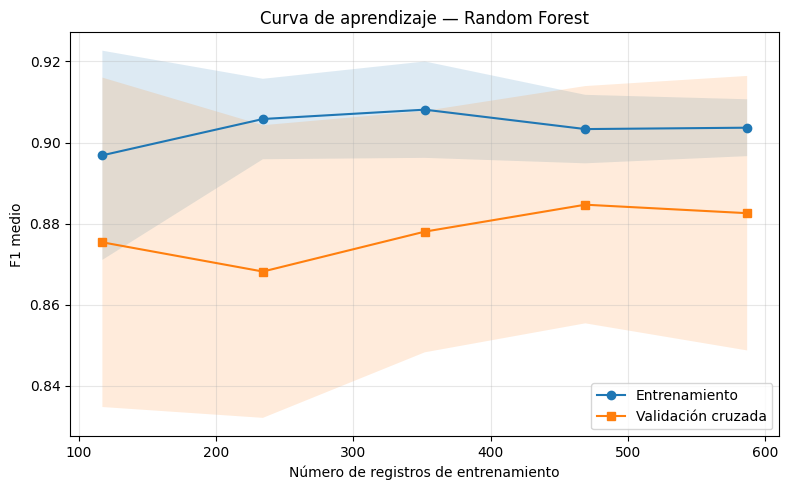

In [11]:

from sklearn.model_selection import learning_curve

mejor_modelo = busquedas["Random Forest"].best_estimator_

train_sizes, train_scores, valid_scores = learning_curve(
    estimator=mejor_modelo,
    X=X_train, y=y_train,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=cv, scoring="f1",
    n_jobs=-1, shuffle=True, random_state=42
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
valid_mean = valid_scores.mean(axis=1)
valid_std = valid_scores.std(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, "o-", label="Entrenamiento")
plt.plot(train_sizes, valid_mean, "s-", label="Validación cruzada")

plt.fill_between(train_sizes, train_mean - train_std,
                 train_mean + train_std, alpha=0.15)
plt.fill_between(train_sizes, valid_mean - valid_std,
                 valid_mean + valid_std, alpha=0.15)

plt.xlabel("Número de registros de entrenamiento")
plt.ylabel("F1 medio")
plt.title("Curva de aprendizaje — Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 2.6. Comparación con el modelo de referencia

Para contextualizar el desempeño de los clasificadores entrenados, se utilizará `DummyClassifier` como modelo de referencia (*baseline*), con la estrategia `most_frequent`.

Este clasificador predice siempre la clase mayoritaria identificada en los datos de entrenamiento, sin utilizar las características predictoras. Por tanto, permite establecer un punto de comparación básico para evaluar el valor agregado de los modelos de aprendizaje automático.

Se aplicará validación cruzada estratificada de cinco pliegues, utilizando las mismas métricas definidas para regresión logística, KNN y Random Forest.

El desempeño del modelo de referencia se incorporará a la tabla comparativa, sin modificar la selección de hiperparámetros realizada anteriormente.

In [12]:

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

baseline = DummyClassifier(strategy="most_frequent")

scores_baseline = cross_validate(
    baseline, X_train, y_train,
    cv=cv, scoring=scoring, n_jobs=-1
)

resultado_baseline = {
    "Modelo": "DummyClassifier",
    "F1": scores_baseline["test_F1"].mean(),
    "Recall": scores_baseline["test_Recall"].mean(),
    "Precision": scores_baseline["test_Precision"].mean(),
    "Accuracy": scores_baseline["test_Accuracy"].mean(),
    "ROC-AUC": scores_baseline["test_ROC_AUC"].mean(),
    "Hiperparámetros": "strategy=most_frequent"
}

tabla_final_cv = pd.concat([
    tabla_cv.drop(columns="Tiempo (s)", errors="ignore"),
    pd.DataFrame([resultado_baseline])
], ignore_index=True)

tabla_final_cv = tabla_final_cv.sort_values("F1", ascending=False)
display(tabla_final_cv.round(4))


,Modelo,F1,Recall,Precision,Accuracy,ROC-AUC,Hiperparámetros
0,Random Forest,0.8863,0.9163,0.8589,0.8692,0.9332,"max_depth=5, min_samples_leaf=5, n_estimators=200"
1,Regresión logística,0.8751,0.8917,0.8604,0.8583,0.9256,"C=0.1, class_weight=None"
2,KNN,0.8720,0.8793,0.8650,0.8570,0.9162,"n_neighbors=15, weights=uniform"
3,DummyClassifier,0.7123,1.0000,0.5531,0.5531,0.5000,strategy=most_frequent


**Análisis comparativo y selección del modelo**

Los tres algoritmos de aprendizaje automático superaron al modelo de referencia `DummyClassifier`, cuyo F1 fue de 0.7123. Este resultado evidencia que las características predictoras aportan información útil para la clasificación de `HeartDisease`.

Aunque el modelo de referencia alcanzó un recall de 1.0, este resultado se debe a que predice siempre la clase positiva. Su precisión de 0.5531 y ROC-AUC de 0.5 evidencian su limitada capacidad discriminativa.

Entre los modelos entrenados, **Random Forest obtuvo el mayor F1 de validación cruzada (0.8863)**, seguido de regresión logística (0.8751) y KNN (0.8720). También presentó el mayor recall (0.9163) y ROC-AUC (0.9332).

La mejor configuración de Random Forest fue:

- `n_estimators = 200`
- `max_depth = 5`
- `min_samples_leaf = 5`

Las curvas de validación mostraron que limitar la profundidad de los árboles favorece la generalización, mientras que la curva de aprendizaje evidenció un desempeño relativamente estable y una diferencia moderada entre entrenamiento y validación.

En consecuencia, **se selecciona Random Forest como modelo final**, de acuerdo con el criterio de F1 establecido previamente. Aunque las diferencias frente a los otros algoritmos son pequeñas y no se ha realizado una prueba de significancia estadística, los resultados respaldan su selección para la evaluación sobre el conjunto de prueba reservado.

## **3. Evaluación del modelo**
---

En esta sección debe reportar el desempeño del modelo sobre la partición de datos de pruebas (test). Considere que dispone de las siguientes métricas:

- **Clasificación**: accuracy, precision, recall, f1-score, AUC, matriz de confusión, etc.
- **Regresión**: $r^2$, error cuadrático medio, error absoluto medio, etc.
- **Agrupamiento**: coeficiente de silueta, índice de Davies-Bouldin, etc.

Los resultados se deben presentar usando tablas y figuras además del análisis detallado respectivo.

In [ ]:
# ---**INGRESE SU CÓDIGO**---


### 3.1. Evaluación sobre el conjunto de prueba

Una vez seleccionado Random Forest como el modelo con mayor F1 durante la validación cruzada, se evaluará su capacidad de generalización utilizando el conjunto de prueba reservado en la fase 3.

Este conjunto contiene 184 registros (20 % del total) y no fue utilizado durante el entrenamiento ni la optimización de hiperparámetros.

Se calcularán las siguientes métricas:

- **Accuracy:** proporción de predicciones correctas.
- **Precision:** proporción de predicciones positivas que corresponden realmente a pacientes con `HeartDisease = 1`.
- **Recall:** proporción de casos positivos identificados correctamente.
- **F1-score:** media armónica entre precisión y recall.
- **ROC-AUC:** capacidad del modelo para discriminar entre las dos clases a diferentes umbrales de decisión.

Los resultados se compararán con los obtenidos durante la validación cruzada para identificar posibles diferencias entre el desempeño estimado y el observado sobre datos no utilizados previamente.

In [13]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

# Recuperar el mejor modelo seleccionado en la sección 2.
modelo_final = busquedas["Random Forest"].best_estimator_

# Predicciones sobre el conjunto de prueba.
y_pred = modelo_final.predict(X_test)
y_proba = modelo_final.predict_proba(X_test)[:, 1]

# Métricas de evaluación.
metricas_test = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_proba)
}

# Comparación con los resultados de validación cruzada.
metricas_cv = resultados_cv.loc[
    resultados_cv["Modelo"] == "Random Forest"
].iloc[0]

comparacion = pd.DataFrame({
    "Métrica": list(metricas_test.keys()),
    "Validación cruzada": [
        metricas_cv["Accuracy"], metricas_cv["Precision"],
        metricas_cv["Recall"], metricas_cv["F1"], metricas_cv["ROC-AUC"]
    ],
    "Prueba": list(metricas_test.values())
})

comparacion["Diferencia"] = comparacion["Prueba"] - comparacion["Validación cruzada"]

display(comparacion.round(4))
print(f"Registros evaluados: {len(y_test)}")
print("✓ Evaluación del conjunto de prueba completada.")


,Métrica,Validación cruzada,Prueba,Diferencia
0,Accuracy,0.8692,0.8967,0.0275
1,Precision,0.8589,0.8807,0.0218
2,Recall,0.9163,0.9412,0.0249
3,F1,0.8863,0.9100,0.0237
4,ROC-AUC,0.9332,0.9342,0.0011


Registros evaluados: 184
✓ Evaluación del conjunto de prueba completada.


**Análisis de los resultados sobre el conjunto de prueba**

El modelo Random Forest alcanzó un F1 de **0.9100** sobre los 184 registros de prueba, superando ligeramente el valor obtenido durante la validación cruzada (0.8863). Este resultado indica un equilibrio favorable entre precisión (0.8807) y recall (0.9412).

El recall obtenido muestra que el modelo identifica correctamente el 94.12 % de los casos positivos de `HeartDisease`, mientras que la precisión indica que el 88.07 % de las predicciones positivas son correctas.

Por su parte, el ROC-AUC alcanzó 0.9342, un valor muy cercano al obtenido durante la validación cruzada (0.9332), lo que evidencia estabilidad en la capacidad discriminativa del clasificador entre ambas evaluaciones.

En conjunto, los resultados respaldan la capacidad de generalización del modelo sobre la partición de prueba utilizada. Sin embargo, estas conclusiones corresponden al conjunto de datos disponible y no constituyen una validación clínica ni garantizan el mismo desempeño en poblaciones diferentes.

### 3.2. Matriz de confusión

Se construirá la matriz de confusión del modelo Random Forest sobre el conjunto de prueba, con el propósito de examinar la distribución de las predicciones correctas e incorrectas.

Se identificarán los verdaderos negativos (TN), falsos positivos (FP), falsos negativos (FN) y verdaderos positivos (TP).

En particular, se analizarán los falsos negativos, correspondientes a registros con `HeartDisease = 1` que el modelo clasifica incorrectamente como negativos, debido a su relevancia en el contexto del problema.

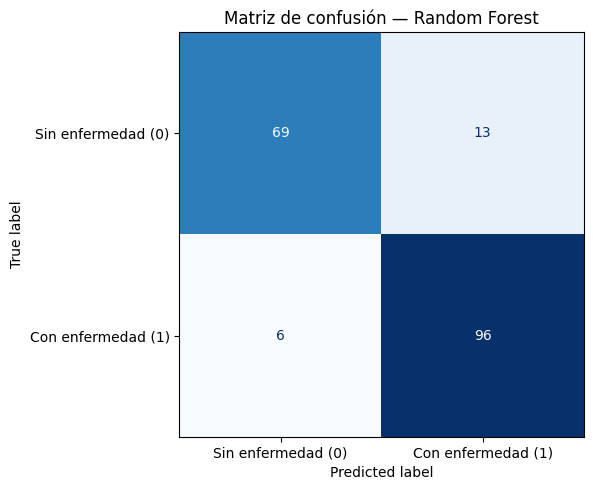

Verdaderos negativos (TN): 69
Falsos positivos (FP): 13
Falsos negativos (FN): 6
Verdaderos positivos (TP): 96


In [14]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Sin enfermedad (0)", "Con enfermedad (1)"]
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

ax.set_title("Matriz de confusión — Random Forest")
plt.tight_layout()
plt.show()

print(f"Verdaderos negativos (TN): {tn}")
print(f"Falsos positivos (FP): {fp}")
print(f"Falsos negativos (FN): {fn}")
print(f"Verdaderos positivos (TP): {tp}")


**Análisis de la matriz de confusión**

La matriz de confusión muestra que Random Forest clasificó correctamente 165 de los 184 registros de prueba, con 69 verdaderos negativos y 96 verdaderos positivos.

Se identificaron 19 errores de clasificación, distribuidos en 13 falsos positivos y 6 falsos negativos.

De los 102 registros pertenecientes a la clase positiva (`HeartDisease = 1`), el modelo identificó correctamente 96, lo que corresponde a un recall de 0.9412. Este resultado indica una alta capacidad para reconocer los casos positivos en el conjunto evaluado.

No obstante, los seis falsos negativos representan una limitación relevante, especialmente si se considera una posible aplicación de apoyo a decisiones clínicas, donde omitir casos positivos puede implicar riesgos.

En conjunto, la matriz respalda las métricas obtenidas previamente y evidencia un buen desempeño de clasificación, aunque persisten errores que deben considerarse al interpretar los resultados.

### 3.3. Curva ROC y capacidad discriminativa

Se construirá la curva ROC (*Receiver Operating Characteristic*) del modelo Random Forest sobre el conjunto de prueba.

Esta curva representa la relación entre la tasa de verdaderos positivos (TPR) y la tasa de falsos positivos (FPR) para diferentes umbrales de clasificación.

El área bajo la curva (ROC-AUC) permitirá evaluar la capacidad del modelo para distinguir entre las clases positiva y negativa, independientemente de un umbral específico.

Se incluirá como referencia la diagonal correspondiente a un clasificador sin capacidad discriminativa (ROC-AUC = 0.5).

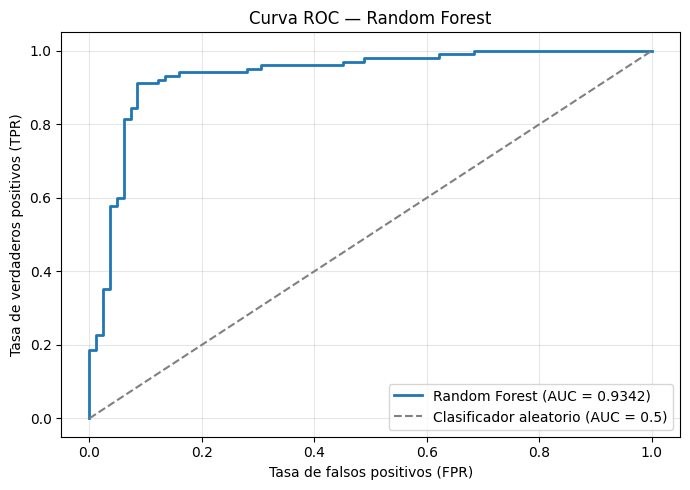

In [15]:

from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, linewidth=2, label=f"Random Forest (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Clasificador aleatorio (AUC = 0.5)")

plt.xlabel("Tasa de falsos positivos (FPR)")
plt.ylabel("Tasa de verdaderos positivos (TPR)")
plt.title("Curva ROC — Random Forest")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Análisis de la curva ROC**

La curva ROC de Random Forest se sitúa considerablemente por encima de la diagonal correspondiente a un clasificador sin capacidad discriminativa, aproximándose a la esquina superior izquierda del gráfico.

El área bajo la curva alcanzó **ROC-AUC = 0.9342**, lo que evidencia una buena capacidad para distinguir entre los registros positivos y negativos de `HeartDisease` a diferentes umbrales de clasificación.

Este resultado es consistente con el ROC-AUC obtenido durante la validación cruzada (0.9332), cuya diferencia es de aproximadamente 0.001.

En conjunto, la curva ROC respalda los resultados de precisión, recall y F1 obtenidos sobre el conjunto de prueba, mostrando un desempeño discriminativo favorable del modelo seleccionado.

### 3.4. Conclusiones de la evaluación

La evaluación de Random Forest sobre los 184 registros de prueba permitió verificar su desempeño con datos no utilizados durante el entrenamiento ni la selección de hiperparámetros.

El modelo alcanzó una exactitud de 0.8967, precisión de 0.8807, recall de 0.9412, F1 de 0.9100 y ROC-AUC de 0.9342.

La matriz de confusión mostró 165 clasificaciones correctas y 19 incorrectas, incluyendo seis falsos negativos. Estos últimos representan una limitación relevante, considerando las posibles consecuencias de no identificar casos positivos.

Los resultados fueron consistentes con los obtenidos durante la validación cruzada y respaldan la capacidad de generalización del modelo sobre la partición evaluada.

No obstante, el desempeño observado corresponde a un conjunto de datos específico. Su utilización en escenarios clínicos reales requeriría validación externa, evaluación de posibles sesgos y estudios adicionales de confiabilidad.

Adicionalmente, si utilizó un modelo pre-entrenado, debe generar predicciones y mostrar el resultado final de la aplicación del modelo sobre sus datos:

In [ ]:
# ---**INGRESE SU CÓDIGO**---

## **4. Aplicación del modelo**
---

Una vez que haya entrenado y evaluado su modelo, es importante considerar cómo puede ser utilizado en un entorno práctico.

Intente analizar la capacidad del modelo para generalizar nuevos datos que no formaron parte del conjunto de entrenamiento o evaluación.

In [ ]:
# ---**INGRESE SU CÓDIGO**---

### 4.1. Predicción sobre una nueva observación

Para demostrar la aplicación del modelo seleccionado, se utilizará el pipeline de Random Forest entrenado en las secciones anteriores para clasificar un nuevo registro con las 12 características predictoras definidas en la fase 3.

El pipeline permite recibir los datos en su formato original y aplicar automáticamente las transformaciones de imputación y codificación antes de generar la predicción.

Se utilizará un registro hipotético con valores compatibles con las variables del conjunto de datos, sin emplear observaciones del conjunto de prueba.

La aplicación permitirá obtener tanto la clase predicha (`HeartDisease = 0` o `HeartDisease = 1`) como la probabilidad estimada de pertenecer a la clase positiva.

Esta demostración tiene fines exclusivamente académicos y no constituye una herramienta de diagnóstico clínico.

In [16]:

# Registro hipotético para demostrar la aplicación del modelo.
nuevo_registro = {
    "Age": 55,
    "Sex": "M",
    "ChestPainType": "ASY",
    "RestingBP": 140,
    "Cholesterol": 240,
    "FastingBS": 0,
    "RestingECG": "Normal",
    "MaxHR": 130,
    "ExerciseAngina": "Y",
    "Oldpeak": 1.5,
    "ST_Slope": "Flat",
    "Cholesterol_missing": 0
}

X_nuevo = pd.DataFrame([nuevo_registro])[feature_cols]

assert X_nuevo.columns.tolist() == X_train.columns.tolist()
assert X_nuevo.shape == (1, 12)

display(X_nuevo.T.rename(columns={0: "Valor"}))
print("✓ Nuevo registro preparado correctamente.")


,Valor
Age,55
RestingBP,140
Cholesterol,240
MaxHR,130
Oldpeak,1.5
Sex,M
ChestPainType,ASY
FastingBS,0
RestingECG,Normal
ExerciseAngina,Y


✓ Nuevo registro preparado correctamente.


In [17]:

# Predicción de clase y probabilidad.
prediccion = int(modelo_final.predict(X_nuevo)[0])
probabilidad = modelo_final.predict_proba(X_nuevo)[0, 1]

resultado = pd.DataFrame({
    "Resultado": ["Clase predicha", "Probabilidad clase 1"],
    "Valor": [str(prediccion), f"{probabilidad:.2%}"]
})

display(resultado)

if prediccion == 1:
    print("Predicción: HeartDisease = 1 (clase positiva)")
else:
    print("Predicción: HeartDisease = 0 (clase negativa)")

print("Nota: resultado experimental, no constituye un diagnóstico médico.")


,Resultado,Valor
0,Clase predicha,1
1,Probabilidad clase 1,92.99%


Predicción: HeartDisease = 1 (clase positiva)
Nota: resultado experimental, no constituye un diagnóstico médico.


### 4.2. Interpretación de la predicción

Al aplicar el pipeline de Random Forest a un registro hipotético con las 12 características predictoras, el modelo produjo una clasificación positiva (`HeartDisease = 1`) con una probabilidad estimada de **92.99 %** para dicha clase.

Este resultado indica que, de acuerdo con los patrones aprendidos durante el entrenamiento, las características del registro son compatibles con las observaciones clasificadas como positivas en el conjunto de datos.

La demostración confirma que el pipeline permite procesar nuevas observaciones y generar predicciones sin repetir manualmente las transformaciones utilizadas durante el entrenamiento.

No obstante, la probabilidad obtenida corresponde a una estimación del clasificador y no debe interpretarse como una probabilidad clínica validada. La aplicación presentada tiene fines exclusivamente académicos y no constituye un procedimiento de diagnóstico médico.

## 5. Conclusiones

El proyecto permitió desarrollar y evaluar un procedimiento de clasificación supervisada para la variable `HeartDisease`, utilizando las características seleccionadas durante las fases previas.

Se compararon tres algoritmos de aprendizaje automático —regresión logística, KNN y Random Forest— mediante validación cruzada estratificada y optimización de hiperparámetros. Los tres superaron el desempeño del clasificador de referencia `DummyClassifier`.

**Random Forest fue seleccionado como el mejor modelo**, con un F1 de validación cruzada de 0.8863. Su evaluación sobre 184 registros de prueba produjo un F1 de 0.9100, recall de 0.9412 y ROC-AUC de 0.9342, evidenciando un desempeño favorable sobre la partición evaluada.

Las curvas de validación mostraron la importancia de controlar la complejidad del modelo, mientras que la curva de aprendizaje permitió analizar su comportamiento frente al incremento de los datos disponibles.

Finalmente, se demostró la aplicación del pipeline a una nueva observación hipotética, obteniendo tanto la clase predicha como su probabilidad estimada.

Aunque los resultados son favorables, el modelo presenta limitaciones relacionadas con los errores de clasificación, el tamaño y la representatividad del conjunto de datos y la ausencia de validación clínica externa. Por tanto, su aplicación debe entenderse como un ejercicio académico de aprendizaje automático y no como una herramienta de diagnóstico médico.

## **Créditos**
---

* **Profesor:** [Fabio Augusto Gonzalez](https://dis.unal.edu.co/~fgonza/)
* **Asistente docente :**
  * [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Diseño de imágenes:**
    - [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*